In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import stan
from pathlib import Path

import nest_asyncio
nest_asyncio.apply()

import logging
logging.getLogger().setLevel(logging.ERROR)

In [13]:
## Output folder for figures
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

In [14]:
## Load data
df = pd.read_csv('processed_data/selective_retention.csv', parse_dates=['date_prev', 'date_curr'])
df.head()

,X,longitude,latitude,lek_id,date,point_id,six_neighbour_cv,date_prev,date_curr,interval_days,nnd_to_next,persistent
0,0,74.436865,27.800003,Tal Chhapar,2012-10-01,0,0.188504,2012-10-01,2014-02-01,488,1.947405,True
1,1,74.437586,27.800908,Tal Chhapar,2012-10-01,1,0.275553,2012-10-01,2014-02-01,488,4.863054,True
2,2,74.437337,27.801097,Tal Chhapar,2012-10-01,2,0.293247,2012-10-01,2014-02-01,488,13.307303,False
3,3,74.437137,27.800904,Tal Chhapar,2012-10-01,3,0.257615,2012-10-01,2014-02-01,488,6.993262,False
4,4,74.437433,27.800634,Tal Chhapar,2012-10-01,4,0.197662,2012-10-01,2014-02-01,488,2.047064,True


In [15]:
## Colour palettes
fill_cols = {'Tal Chhapar': '#B5542D', 'Velavadar Lek 1': '#1F6F8B', 'Velavadar Lek 2': '#3FA7A3'}
point_cols = {'Tal Chhapar': '#D97A52', 'Velavadar Lek 1': '#15556B', 'Velavadar Lek 2': '#2B7E7B'}

In [16]:
## Encode lek ID in a numerical variable
lek_levels = sorted(df['lek_id'].unique())
lek_map = {lek: i for i, lek in enumerate(lek_levels)}
df['site_id'] = df['lek_id'].map(lek_map).astype(int)

In [17]:
cv_centred = df['six_neighbour_cv'] - df['six_neighbour_cv'].mean()
cv_z = np.array(cv_centred / df['six_neighbour_cv'].std())

## Specify size axis
cv_min, cv_max = float(cv_z.min()), float(cv_z.max())
cv_grid = np.linspace(cv_min, cv_max, 200)
cv_original = cv_grid * df['six_neighbour_cv'].std() + df['six_neighbour_cv'].mean()

In [18]:
## Model territory retention as a function of six-neighbour CV for each lek
retention_lek_mod = """
data {
    int<lower=1> n_points;
    int<lower=1> n_sites;
    array[n_points] int<lower=1, upper=n_sites> site_id;
    array[n_points] int<lower=0, upper=1> persistent;
    vector[n_points] cv;
}

parameters {
    vector[n_sites] alpha;
    vector[n_sites] beta;
}

model {
    alpha ~ normal(0, 1);
    beta  ~ normal(0, 1);

    persistent ~ bernoulli_logit(alpha[site_id] + beta[site_id] .* cv);
}
"""

In [19]:
retention_lek_data = {
    'n_points': len(df),
    'n_sites': len(lek_levels),
    'site_id': (df['site_id'] + 1).to_numpy(),
    'persistent': df['persistent'].astype(int).to_numpy(),
    'cv': cv_z
}

posterior_lek = stan.build(retention_lek_mod, data=retention_lek_data)
fit_lek = posterior_lek.sample(num_chains=4, num_warmup=1000, num_samples=1000)

Building...



Building: found in cache, done.Sampling:   0%
Sampling:   8% (600/8000)
Sampling:  16% (1300/8000)
Sampling:  25% (2000/8000)
Sampling:  50% (4000/8000)
Sampling:  68% (5400/8000)
Sampling:  84% (6700/8000)
Sampling: 100% (8000/8000)
Sampling: 100% (8000/8000), done.
Messages received during sampling:
  Gradient evaluation took 9.9e-05 seconds
  1000 transitions using 10 leapfrog steps per transition would take 0.99 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 9.7e-05 seconds
  1000 transitions using 10 leapfrog steps per transition would take 0.97 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 0.000123 seconds
  1000 transitions using 10 leapfrog steps per transition would take 1.23 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 0.000121 seconds
  1000 transitions using 10 leapfrog steps per transition would take 1.21 seconds.
  Adjust your expectations accordingly!


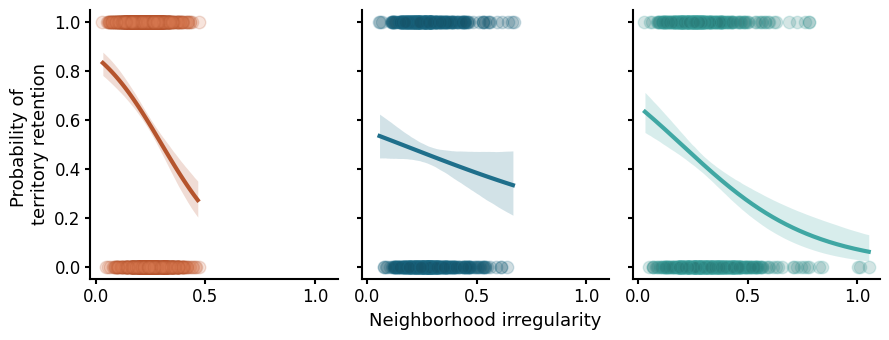

In [ ]:
fig,axes = plt.subplots(1, 3, figsize=(9, 3.5), sharex=True, sharey=True)

for i,lek in enumerate(lek_levels):
    ax = axes[i]
    df_lek = df[df['lek_id'] == lek].copy()
    cv_range = (cv_original >= df_lek['six_neighbour_cv'].min()) & (cv_original <= df_lek['six_neighbour_cv'].max())

    # Compute posterior retention probabilities
    mu = fit_lek['alpha'][i,:].reshape(-1,1) + fit_lek['beta'][i,:].reshape(-1,1) * cv_grid[None,:]
    y = scipy.special.expit(mu)
    y_mean = np.mean(y, axis=0)
    y_lower,y_upper = np.quantile(y, [0.025,0.975], axis=0)

    # Plot model fits
    ax.plot(cv_original[cv_range], y_mean[cv_range], linewidth=3, color=fill_cols[lek], label=lek)
    ax.fill_between(cv_original[cv_range], y_lower[cv_range], y_upper[cv_range], color=fill_cols[lek], alpha=0.2, linewidth=0)

    # Add scatter to the plot
    ax.scatter(df_lek['six_neighbour_cv'], df_lek['persistent'], s=80, color=point_cols[lek], edgecolor=fill_cols[lek], alpha=0.2, zorder=4)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)


axes[1].set_xlabel('Neighborhood irregularity', fontsize=13)
axes[0].set_ylabel('Probability of \nterritory retention', fontsize=13)

plt.tight_layout()
plt.savefig(out_dir/'mod_territory_retention.png', dpi=300, bbox_inches='tight')

In [21]:
## Compute the change in retention probability for each lek
retention_lower = scipy.special.expit(fit_lek['alpha'] + fit_lek['beta'] * -0.5)
retention_upper = scipy.special.expit(fit_lek['alpha'] + fit_lek['beta'] * 0.5)

p_retention_lek = retention_upper - retention_lower

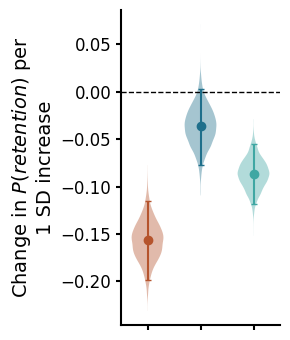

In [22]:
fig, ax = plt.subplots(figsize=(3, 3.5))

## x-positions for categorical variables
x_pos = np.arange(len(lek_levels))

for i,lek in enumerate(lek_levels):
    samples = p_retention_lek[i,:]

    # Violin plot
    parts = ax.violinplot(samples, positions=[x_pos[i]], widths=0.6, showmeans=False, showmedians=False, showextrema=False)

    for pc in parts['bodies']:
        pc.set_facecolor(fill_cols.get(lek))
        pc.set_edgecolor('none')
        pc.set_alpha(0.4)

    # Overlay median and posterior interval
    median = np.median(samples)
    lower, upper = np.quantile(samples, [0.025, 0.975])

    ax.errorbar(x_pos[i], median, yerr=[[median-lower], [upper-median]], fmt='o', color=fill_cols.get(lek), markersize=6, capsize=2, zorder=3)

ax.axhline(0, linestyle='--', color='black', linewidth=1)
ax.set_xlim(-0.5, len(lek_levels) - 0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels([])

ax.set_ylabel('Change in $P(retention)$ per \n1 SD increase', fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5)

plt.tight_layout()
plt.savefig(out_dir/'mod_causal_territory_retention.png', dpi=300, bbox_inches='tight')